# Notebook 11 – EDA Visualization
## `11_EDA_Visualization.ipynb`

### Learning objectives
Use Matplotlib and Seaborn to select useful graphs, interpret their shapes and relationships, and record insights. Each plot should answer a question—not exist just to decorate a report.

This notebook uses a reproducible sample retail dataset. Replace it with your own dataset when ready.

## 1. What is EDA visualization?

Exploratory Data Analysis (EDA) visualization uses graphs to understand distributions, compare groups, inspect relationships, and spot unusual observations.

**Simple example:** A bar chart compares the marks of students in different subjects.

**Real-world example:** A line plot shows daily temperature changes.

**Business example:** A company compares sales by product category.

**AI/ML use case:** Visualizations help identify skewed features, outliers, relationships, and data-quality issues before modeling.

**Why it matters:** The right plot can reveal patterns that are difficult to notice in a table. Always interpret the graph in the context of the data.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
np.random.seed(42)

n = 120
dates = pd.date_range("2026-01-01", periods=30, freq="D")
daily_sales = np.random.normal(500, 70, size=30).round(2)
categories = np.random.choice(["A", "B", "C"], size=n, p=[0.5, 0.3, 0.2])
price = np.random.normal(50, 12, size=n).clip(10, 100)
units = np.random.poisson(8, size=n) + 1
sales = price * units + np.random.normal(0, 25, size=n)
segment = np.random.choice(["Consumer", "Business", "Home Office"], size=n)

df = pd.DataFrame({
    "category": categories,
    "price": price.round(2),
    "units": units,
    "sales": sales.round(2),
    "segment": segment
})
daily_df = pd.DataFrame({"date": dates, "sales": daily_sales})
df.head()

,category,price,units,sales,segment
0,B,59.49,7,415.81,Consumer
1,A,39.09,10,420.19,Consumer
2,A,66.83,6,414.59,Business
3,A,33.18,3,90.27,Home Office
4,A,57.04,9,532.67,Consumer


## 2. Histogram – distribution of a numerical feature

**Why selected:** A histogram groups numeric values into bins so we can see where observations are concentrated and whether the distribution is skewed or multi-peaked.

**Simple example:** Count students in score ranges such as 0–20, 21–40, and so on.

**Real-world example:** Examine the distribution of delivery times.

**Business example:** Understand the range of order values.

**AI/ML use case:** Check feature scale and skew before selecting preprocessing steps.

**Interpretation / insight:** Look for the most common range, overall spread, skew, and unusual tails. The exact conclusion depends on the plotted data.

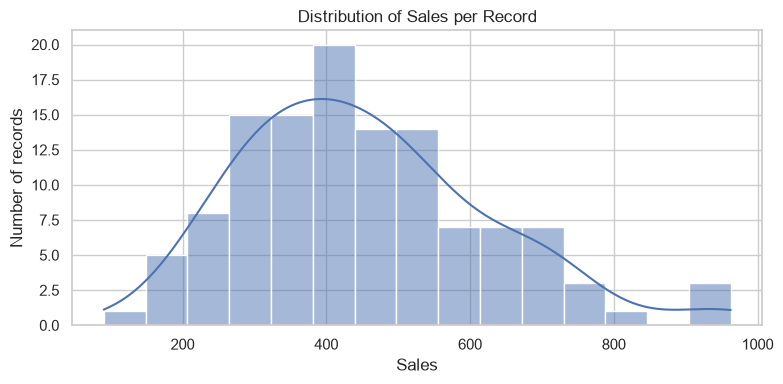

In [2]:
plt.figure(figsize=(8, 4))
sns.histplot(data=df, x="sales", bins=15, kde=True)
plt.title("Distribution of Sales per Record")
plt.xlabel("Sales")
plt.ylabel("Number of records")
plt.tight_layout()
plt.show()

## 3. Box plot – spread and potential outliers

**Why selected:** A box plot summarizes the median, quartiles, spread, and potential outliers.

**Simple example:** Compare the spread of test scores across two classes.

**Real-world example:** Inspect variation in package delivery times.

**Business example:** Compare order-value variation across product categories.

**AI/ML use case:** Flag potential outliers for investigation; do not automatically delete them.

**Interpretation / insight:** Compare median lines and box lengths. Points outside whiskers are potential outliers under the plotting rule, not proof of errors.

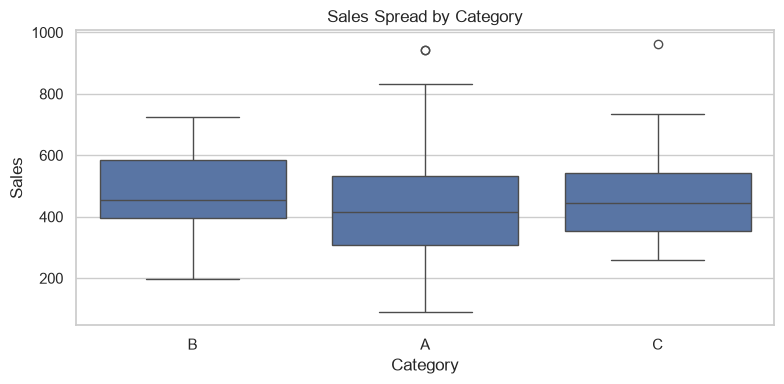

In [3]:
plt.figure(figsize=(8, 4))
sns.boxplot(data=df, x="category", y="sales")
plt.title("Sales Spread by Category")
plt.xlabel("Category")
plt.ylabel("Sales")
plt.tight_layout()
plt.show()

## 4. Bar chart – compare aggregated values

**Why selected:** A bar chart compares a summary such as total or average sales across categories.

**Simple example:** Compare the number of books sold by genre.

**Real-world example:** Compare monthly electricity use by building.

**Business example:** Compare total revenue by product category.

**AI/ML use case:** Group comparisons may suggest segments worth exploring, though a bar chart alone does not establish causation.

**Interpretation / insight:** Identify the highest and lowest group and check whether the difference is meaningful for the business.

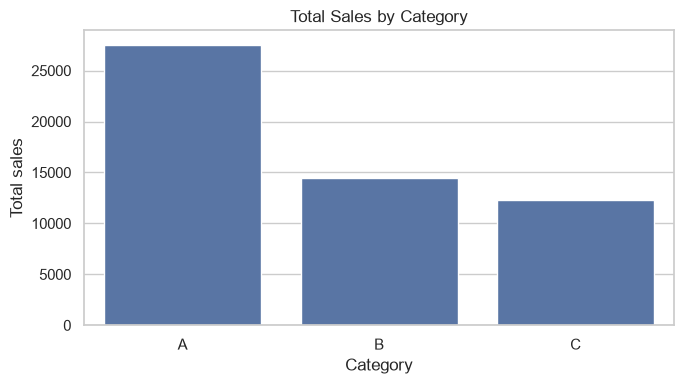

,category,sales
0,A,27557.93
1,B,14461.98
2,C,12289.85


In [4]:
category_sales = df.groupby("category", as_index=False)["sales"].sum().sort_values("sales", ascending=False)
plt.figure(figsize=(7, 4))
sns.barplot(data=category_sales, x="category", y="sales")
plt.title("Total Sales by Category")
plt.xlabel("Category")
plt.ylabel("Total sales")
plt.tight_layout()
plt.show()
category_sales

## 5. Count plot – compare category frequencies

**Why selected:** A count plot counts rows in each category without requiring a separate aggregation step.

**Simple example:** Count students in each course.

**Real-world example:** Count support tickets by issue type.

**Business example:** Compare how many orders come from each customer segment.

**AI/ML use case:** Inspect class frequencies for a classification target or category imbalance.

**Interpretation / insight:** A larger bar means more records in that category; it does not necessarily mean greater revenue or profit.

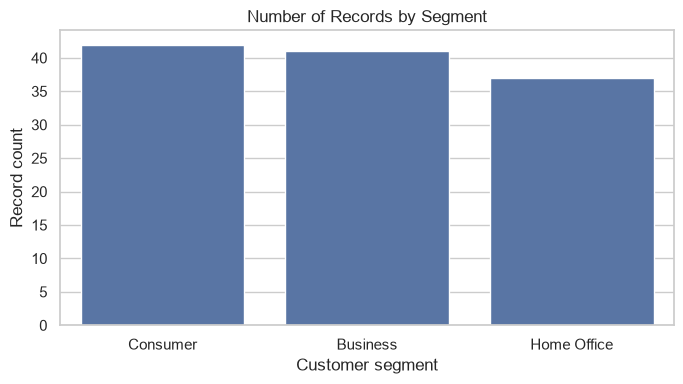

In [5]:
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="segment", order=df["segment"].value_counts().index)
plt.title("Number of Records by Segment")
plt.xlabel("Customer segment")
plt.ylabel("Record count")
plt.tight_layout()
plt.show()

## 6. Scatter plot – relationship between two numeric features

**Why selected:** A scatter plot shows paired numeric values and can reveal positive/negative relationships, clusters, and unusual points.

**Simple example:** Compare hours studied with exam score.

**Real-world example:** Compare car age with resale price.

**Business example:** Compare unit price with units sold.

**AI/ML use case:** Explore feature relationships and possible nonlinear patterns. Correlation is not proof of causation.

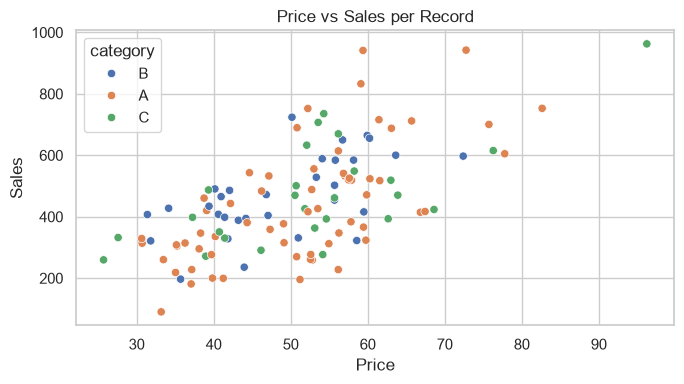

In [8]:
plt.figure(figsize=(7, 4))
sns.scatterplot(data=df, x="price", y="sales", hue="category")
plt.title("Price vs Sales per Record")
plt.xlabel("Price")
plt.ylabel("Sales")
plt.tight_layout()
plt.show()

## 7. Line plot – trends over ordered time

**Why selected:** A line plot connects observations in time order, making trends and fluctuations easier to see.

**Simple example:** Track daily steps over one week.

**Real-world example:** Track a river's water level each day.

**Business example:** Monitor daily revenue.

**AI/ML use case:** Explore trend and seasonality before forecasting. Time-based data must be split chronologically when appropriate.

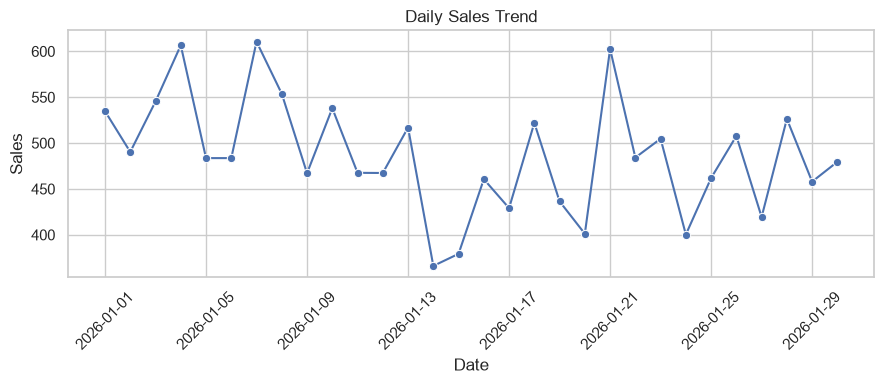

In [9]:
plt.figure(figsize=(9, 4))
sns.lineplot(data=daily_df, x="date", y="sales", marker="o")
plt.title("Daily Sales Trend")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 8. Violin plot – compare distributions across groups

**Why selected:** A violin plot combines a distribution-density shape with a view of how values vary within each group.

**Simple example:** Compare score distributions for different classrooms.

**Real-world example:** Compare waiting times at different clinics.

**Business example:** Compare order-value distributions by customer segment.

**AI/ML use case:** Identify differences in feature distributions across groups or labels.

**Interpretation / insight:** Wider parts indicate more observations around those values according to the estimated density. Small groups can make density estimates unstable.

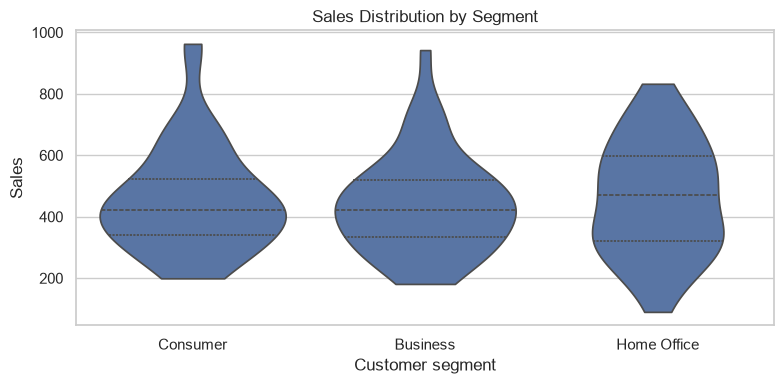

In [10]:
plt.figure(figsize=(8, 4))
sns.violinplot(data=df, x="segment", y="sales", inner="quartile", cut=0)
plt.title("Sales Distribution by Segment")
plt.xlabel("Customer segment")
plt.ylabel("Sales")
plt.tight_layout()
plt.show()

## 9. Pair plot – inspect several numeric relationships

**Why selected:** A pair plot displays pairwise relationships among selected numeric variables and their individual distributions.

**Simple example:** Inspect height, weight, and age together.

**Real-world example:** Explore how house size, age, and price relate.

**Business example:** Compare price, units, and sales across orders.

**AI/ML use case:** Explore potential feature relationships before feature selection.

**Caution:** Pair plots can become crowded on large datasets. Select a few useful columns or sample rows.

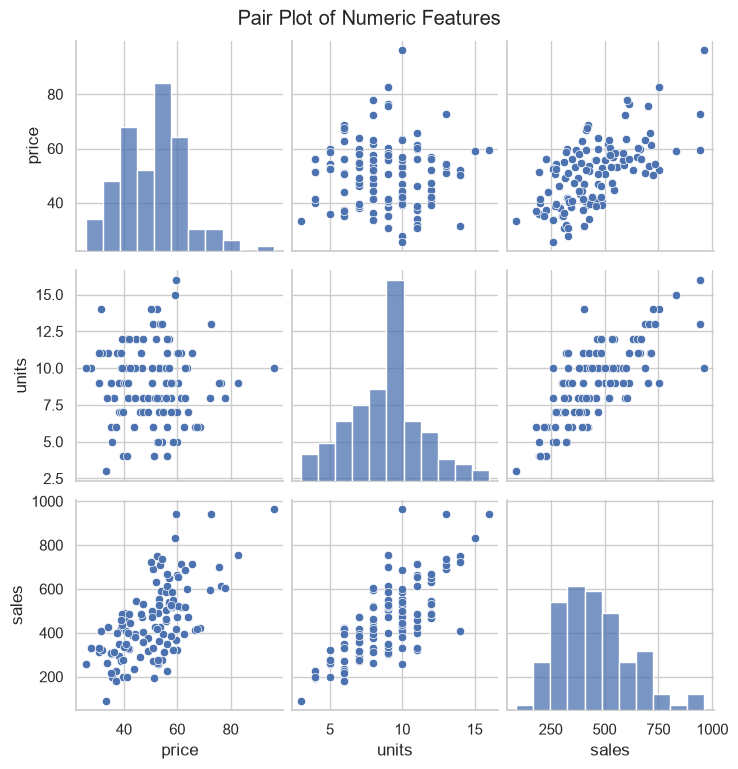

In [11]:
sns.pairplot(df[["price", "units", "sales"]], diag_kind="hist")
plt.suptitle("Pair Plot of Numeric Features", y=1.02)
plt.show()

## 10. Heatmap – visualize a correlation matrix

**Why selected:** A heatmap uses color to summarize a matrix, often a numeric correlation matrix.

**Simple example:** Compare how similar several students' subject scores are.

**Real-world example:** Explore relationships among weather measurements.

**Business example:** Check relationships among price, units, discount, and sales.

**AI/ML use case:** Screen for strongly correlated numeric features and potential multicollinearity. Correlation alone does not determine which feature should be removed.

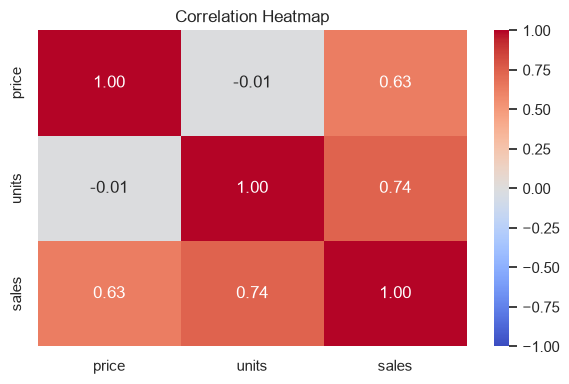

,price,units,sales
price,1.000000,-0.011403,0.632116
units,-0.011403,1.000000,0.736271
sales,0.632116,0.736271,1.000000


In [12]:
corr = df[["price", "units", "sales"]].corr(numeric_only=True)
plt.figure(figsize=(6, 4))
sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f")
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()
corr

## 11. Distribution plot – inspect shape with density

**Why selected:** A density curve helps visualize the shape of a numeric distribution. In Seaborn, `kdeplot` estimates a smooth density; it is not a count chart.

**Simple example:** See whether exam scores cluster around a typical value.

**Real-world example:** Inspect distribution of commute times.

**Business example:** Understand typical customer spending.

**AI/ML use case:** Investigate skewness and compare feature distributions before transformations.

**Interpretation / insight:** Look for peaks, tails, and asymmetry. Density curves are estimates and may be misleading for very small samples.

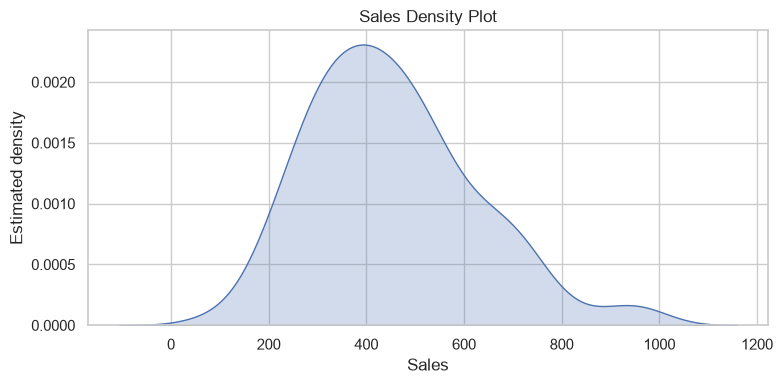

In [13]:
plt.figure(figsize=(8, 4))
sns.kdeplot(data=df, x="sales", fill=True)
plt.title("Sales Density Plot")
plt.xlabel("Sales")
plt.ylabel("Estimated density")
plt.tight_layout()
plt.show()

## 12. Choosing meaningful visualizations

| Question | Useful plot |
|---|---|
| How are numeric values distributed? | Histogram, density plot, box plot |
| Which category has the highest total or average? | Bar chart |
| How many rows belong to each class? | Count plot |
| Do two numeric variables move together? | Scatter plot |
| How does a value change over time? | Line plot |
| How do distributions differ by group? | Box plot, violin plot |
| How do several numeric features relate? | Pair plot, correlation heatmap |

### Final checklist
- State the question before making a plot.
- Label axes and use a clear title.
- Check units, missing values, and sample size.
- Describe the observed pattern without claiming causation from correlation.
- Write one evidence-based insight after each plot.
- Avoid unnecessary plots that do not help answer the analysis question.